# 01 · Data Preparation — Kidaw'ida ↔ Swahili Machine Translation

**Project:** Machine Translation for an under-resourced African language (Kidaw'ida / Taita, ISO 639-3 `dav`) paired with Kiswahili (`swa`).

**Dataset:** `thinkKenya/kenyan-low-resource-language-data`, config `dav_swa` (Mbogho et al., 2024; Lacuna Fund; CC-BY-4.0).

**What this notebook does**
1. Mounts Google Drive and creates the project folder structure.
2. Loads the gated dataset from Hugging Face.
3. Inspects the raw data (sizes, lengths, duplicates, empty/odd rows).
4. Normalises text (Unicode, apostrophes, whitespace) — *no lowercasing*.
5. Filters noisy pairs and logs how many rows each rule removed.
6. Removes train↔test **leakage** so the test score is honest.
7. Creates a validation split and nested 25% / 50% / 100% training subsets (for experiment E5).
8. Computes corpus statistics + figures for the report.
9. Saves everything to Drive.

Runtime: **CPU is enough** for this notebook (no GPU needed).

## 1. Mount Google Drive and create project folders

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/kidawida-mt'
DATA_DIR    = f'{PROJECT_DIR}/data'          # cleaned splits (small CSVs)
RAW_DIR     = f'{PROJECT_DIR}/data/raw'      # untouched snapshot of the original data
FIG_DIR     = f'{PROJECT_DIR}/figures'       # plots for the report
RESULTS_DIR = f'{PROJECT_DIR}/results'       # stats / metrics JSON
MODELS_DIR  = f'{PROJECT_DIR}/models'        # used by later notebooks

for d in [DATA_DIR, RAW_DIR, FIG_DIR, RESULTS_DIR, MODELS_DIR]:
    os.makedirs(d, exist_ok=True)
print('Project folder:', PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/kidawida-mt


## 2. Install / import libraries

In [ ]:
!pip -q install -U datasets huggingface_hub

import re, json, random, unicodedata
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option('display.max_colwidth', 120)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 15.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.23.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.


## 3. Log in to Hugging Face (dataset is gated)

You must have clicked **"Agree and access repository"** on the dataset page while logged in.

**Recommended:** in Colab, open the 🔑 *Secrets* panel (left sidebar) → add a secret named `HF_TOKEN` with a **read** token from https://huggingface.co/settings/tokens → enable notebook access.
The cell falls back to an interactive login box if the secret isn't set.

In [ ]:
from huggingface_hub import login
try:
    from google.colab import userdata
    login(token=userdata.get('HF_TOKEN'))
    print('Logged in with Colab secret HF_TOKEN')
except Exception as e:
    print('No HF_TOKEN secret found -> interactive login')
    from huggingface_hub import notebook_login
    notebook_login()

## 4. Load the dataset

In [ ]:
from datasets import load_dataset

ds = load_dataset("thinkKenya/kenyan-low-resource-language-data", "dav_swa")
print(ds)
print('\nExample record:', ds['train'][0])

README.md:   0%|          | 0.00/5.83k [00:00<?, ?B/s]

dav_swa/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.16MB            

dav_swa/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

dav_swa/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  294kB            

dav_swa/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/21329 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5333 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'translation'],
        num_rows: 21329
    })
    test: Dataset({
        features: ['id', 'translation'],
        num_rows: 5333
    })
})

Example record: {'id': 25335, 'translation': {'dav': "Ukaniw'ona wadazamiliwa ni ini.", 'swa': 'Akiniona huwa simfurahishi'}}


In [ ]:
# Flatten {'translation': {'dav': ..., 'swa': ...}} into plain columns
def to_df(split):
    rows = []
    for ex in ds[split]:
        tr = ex['translation']
        rows.append({'id': ex.get('id'), 'dav': tr.get('dav'), 'swa': tr.get('swa')})
    return pd.DataFrame(rows)

raw_train = to_df('train')
raw_test  = to_df('test')
print('raw train:', raw_train.shape, '| raw test:', raw_test.shape)

# Keep an untouched copy of the original data on Drive (only a few MB)
raw_train.to_csv(f'{RAW_DIR}/raw_train.csv', index=False)
raw_test.to_csv(f'{RAW_DIR}/raw_test.csv', index=False)
raw_train.sample(10, random_state=SEED)

raw train: (21329, 3) | raw test: (5333, 3)


,id,dav,swa
11051,2333,Kusenekane vilambo viseko vako,Usipeane vitu visivyo vyako
8842,746,Ngolo ra wadamu rakucha ngonde.,Mioyo ya wanadamu imekunja ngumi.
10804,12869,W'izighanagha maza ra charo.,Watachunguza mambo ya safari.
7535,18248,Vua ikazoya,Mvua ikianza
1768,7968,Mburi yava,Mbuzi imezaa
1640,24379,Ujha mwana uredaa mariw'a oghala.,Yule mtoto wakuleta maziwa ameenda
7285,1333,Muisanga uhuu wokunda ghumweri ghwa masanga malazi.,Mzalendo huyu anapenda umoja wa kitaifa.
1870,370,Mlisha wapo.,Mchungaji wangu.
15857,6432,Hesie kazi yapo,Saidia kazi yangu
4691,9806,Naw'ekunda kumanya kenyu,Nataka kujua kwenu


## 5. Inspect the raw data

Before cleaning, we look at what problems actually exist. These numbers go into the *Dataset* section of the report.

In [ ]:
def n_words(s):
    return len(str(s).split()) if isinstance(s, str) else 0

def inspect(df, name):
    d = df.copy()
    d['dav_len'] = d['dav'].map(n_words)
    d['swa_len'] = d['swa'].map(n_words)
    report = {
        'rows': len(d),
        'missing/empty dav': int((d['dav_len'] == 0).sum()),
        'missing/empty swa': int((d['swa_len'] == 0).sum()),
        'identical dav==swa': int((d['dav'].str.strip() == d['swa'].str.strip()).sum()),
        'duplicate pairs': int(d.duplicated(subset=['dav', 'swa']).sum()),
        'duplicate dav sentences': int(d.duplicated(subset=['dav']).sum()),
        'mean words dav': round(d['dav_len'].mean(), 2),
        'mean words swa': round(d['swa_len'].mean(), 2),
        'max words dav': int(d['dav_len'].max()),
        'max words swa': int(d['swa_len'].max()),
    }
    print(f'--- {name} ---')
    for k, v in report.items():
        print(f'{k:>25}: {v}')
    return report

raw_report = {'train': inspect(raw_train, 'RAW TRAIN'), 'test': inspect(raw_test, 'RAW TEST')}

# How much do the official train and test splits overlap?
overlap_pairs = set(zip(raw_train.dav, raw_train.swa)) & set(zip(raw_test.dav, raw_test.swa))
overlap_dav   = set(raw_train.dav) & set(raw_test.dav)
print(f'\nTrain/test identical PAIRS: {len(overlap_pairs)}')
print(f'Train/test identical Kidaw\'ida sentences: {len(overlap_dav)}')
raw_report['train_test_pair_overlap'] = len(overlap_pairs)
raw_report['train_test_dav_overlap'] = len(overlap_dav)

--- RAW TRAIN ---
                     rows: 21329
        missing/empty dav: 0
        missing/empty swa: 0
       identical dav==swa: 1
          duplicate pairs: 3052
  duplicate dav sentences: 3289
           mean words dav: 4.35
           mean words swa: 4.39
            max words dav: 25
            max words swa: 25
--- RAW TEST ---
                     rows: 5333
        missing/empty dav: 0
        missing/empty swa: 1
       identical dav==swa: 1
          duplicate pairs: 247
  duplicate dav sentences: 274
           mean words dav: 4.37
           mean words swa: 4.43
            max words dav: 16
            max words swa: 17

Train/test identical PAIRS: 1093
Train/test identical Kidaw'ida sentences: 1194


In [ ]:
# Look at some suspicious rows: very short, very long, and characters used
raw_train['dav_len'] = raw_train['dav'].map(n_words)
print('Shortest pairs:')
display(raw_train.sort_values('dav_len').head(8)[['dav', 'swa']])
print('Longest pairs:')
display(raw_train.sort_values('dav_len', ascending=False).head(5)[['dav', 'swa']])
raw_train = raw_train.drop(columns='dav_len')

# Character inventory: reveals curly quotes, odd symbols, digits, etc.
chars = Counter(''.join(raw_train['dav'].dropna()) + ''.join(raw_train['swa'].dropna()))
non_basic = {c: n for c, n in chars.most_common() if not re.match(r"[A-Za-z0-9 .,']", c)}
print('Non-basic characters (char: count):', non_basic)

Shortest pairs:


,dav,swa
21033,Nachoka.,Nimechoka
21031,bara,paja
8041,Vala,Videle
8036,Mfugho,mifugo
16127,Ndew'imanyikie.,Hawakujulikana.
16148,Kwadiredia,Umetuletea?
8025,vala,videle
16168,Kwaw'enimanya?,Unanijua?


Longest pairs:


,dav,swa
12839,Na ihi katiba mbishi kudeka na madedo kwamba wibadilishe mfumo ghwa elimu ughu ghukoghe wikainja ghwa wunyanya wikar...,Na hii katiba mpya kuna mazungumzo kwamba wabadilishe mfumo wa elimu huu ulioko wakatoa ya darasa la nane wakaleta C...
13322,"Dikengia kwa malagho gha mashomo, wana wabonyere mtihani ghwa klasi cha wunyanya kwawona agha majibu ghifumie gha mw...","Tukiingia kwa mambo ya masomo,watoto wamefanya mtihani wa darasa la nane,umeona haya majibu ya mwaka ulioisha na yal..."
6643,Ndekune vigingi va alama righoragha aha ni Daw'ida na ughu ni mwano na Makueni na ughu ni mwano na Kwale.,Hakuna minara ya kuonyesha mipaka kati ya Taita Taveta na Kaunti za Kwale na Makueni.
16366,Sasa hata mkanekwa wulalo kwamba mzere kilongozi wa elimu ughu mfumonigho ghukaiye angu diwuye kwa ghuja ghwa imbiri...,"Sasa hata mkipewa nafasi mumueleze kiongozi wa elimu kwamba huu mfumo ukae ama turudi kwa ule wa kwanza,mtasema nini?"
19914,Dikengiria kwa wupande ghwa hali ya anga seji yabadilika ngera yakaiakaia wada isanga jaghaluka kiasiki kwa ughu mpa...,Tukiangalia kulingana na tabia nchi unaweza sema hapa hali imebadilika kwa kiwango gani hapa Taita?


Non-basic characters (char: count): {'?': 2639, '/': 176, '!': 168, '�': 116, '-': 53, '~': 43, '"': 32, ';': 12, '(': 11, ')': 11, ':': 8, '`': 6, '_': 4, '[': 2, ']': 1, '%': 1}


## 6. Normalise text

Design decisions (justify these in the report):
- **Unicode NFC** so the same letter is always encoded the same way.
- **Unify apostrophes** (`’ ‘ ʼ \``  → `'`). The apostrophe is part of Kidaw'ida spelling (e.g. *w'ona*), so we standardise it rather than delete it.
- **Unify quotes/dashes**, collapse repeated whitespace, strip ends.
- **No lowercasing**: NLLB is trained on cased text and names/sentence starts carry information. Casing is handled by the subword tokenizer.
- **Punctuation kept**: it's part of what a translation system should output.

In [ ]:
APOSTROPHES = {'\u2019': "'", '\u2018': "'", '\u02bc': "'", '`': "'", '\u00b4': "'"}
QUOTES      = {'\u201c': '"', '\u201d': '"', '\u201e': '"'}
DASHES      = {'\u2013': '-', '\u2014': '-'}
CONTROL     = re.compile(r'[\u0000-\u001f\u007f\u200b\u200e\u200f\ufeff]')

def normalize(text):
    if not isinstance(text, str):
        return ''
    t = unicodedata.normalize('NFC', text)
    for table in (APOSTROPHES, QUOTES, DASHES):
        for k, v in table.items():
            t = t.replace(k, v)
    t = CONTROL.sub(' ', t)
    t = re.sub(r'\s+([.,!?;:])', r'\1', t)   # no space before punctuation
    t = re.sub(r'\s+', ' ', t).strip()
    return t

tests = ["Ukaniw\u2019ona  wadazamiliwa ni ini .", "\u201cHata iji Wavika\u201d\u200b"]
for s in tests:
    print(repr(s), '->', repr(normalize(s)))

for df in (raw_train, raw_test):
    df['dav'] = df['dav'].map(normalize)
    df['swa'] = df['swa'].map(normalize)

'Ukaniw’ona  wadazamiliwa ni ini .' -> "Ukaniw'ona wadazamiliwa ni ini."
'“Hata iji Wavika”\u200b' -> '"Hata iji Wavika"'


## 7. Filter noisy pairs

Each rule is applied in order and the number of removed rows is logged — this table goes straight into the report.

| Rule | Why |
|---|---|
| empty side | nothing to learn |
| identical source and target | not a translation; teaches the model to copy |
| no letters on one side | only numbers/punctuation |
| too long (> `MAX_WORDS`) | rare, slow to train, often concatenated sentences |
| length ratio > `MAX_RATIO` | likely misaligned pair |
| duplicate pair | over-weights repeated sentences |

In [ ]:
MAX_WORDS = 80     # check the "longest pairs" output above; raise if many good long sentences exist
MAX_RATIO = 3.0    # word-count ratio between the two sides
MIN_WORDS_FOR_RATIO = 4  # don't apply ratio rule to very short pairs (e.g. 1 vs 3 words is fine)

def clean(df, name):
    log = [('start', len(df))]
    d = df.copy()

    d = d[(d.dav.str.len() > 0) & (d.swa.str.len() > 0)];            log.append(('empty side', len(d)))
    d = d[d.dav.str.lower() != d.swa.str.lower()];                    log.append(('identical src/tgt', len(d)))
    has_letter = lambda s: bool(re.search(r'[A-Za-z]', s))
    d = d[d.dav.map(has_letter) & d.swa.map(has_letter)];             log.append(('no letters', len(d)))

    dl, sl = d.dav.map(n_words), d.swa.map(n_words)
    d = d[(dl <= MAX_WORDS) & (sl <= MAX_WORDS)];                      log.append((f'> {MAX_WORDS} words', len(d)))

    dl, sl = d.dav.map(n_words), d.swa.map(n_words)
    ratio = np.maximum(dl, sl) / np.maximum(np.minimum(dl, sl), 1)
    bad = (ratio > MAX_RATIO) & (np.maximum(dl, sl) >= MIN_WORDS_FOR_RATIO)
    d = d[~bad];                                                       log.append((f'ratio > {MAX_RATIO}', len(d)))

    d = d.drop_duplicates(subset=['dav', 'swa']);                     log.append(('duplicate pair', len(d)))

    print(f'--- {name} ---')
    rows = []
    for (step, n), (_, prev) in zip(log[1:], log[:-1]):
        rows.append({'rule': step, 'removed': prev - n, 'remaining': n})
    table = pd.DataFrame(rows)
    display(table)
    return d.reset_index(drop=True), table

train_clean, train_log = clean(raw_train, 'TRAIN')
test_clean,  test_log  = clean(raw_test,  'TEST')

--- TRAIN ---


,rule,removed,remaining
0,empty side,0,21329
1,identical src/tgt,1,21328
2,no letters,0,21328
3,> 80 words,0,21328
4,ratio > 3.0,83,21245
5,duplicate pair,3088,18157


--- TEST ---


,rule,removed,remaining
0,empty side,1,5332
1,identical src/tgt,1,5331
2,no letters,1,5330
3,> 80 words,0,5330
4,ratio > 3.0,20,5310
5,duplicate pair,252,5058


In [ ]:
# Inspect what the ratio rule removed, to make sure it's catching misalignments, not good data
dl, sl = raw_train.dav.map(n_words), raw_train.swa.map(n_words)
ratio = np.maximum(dl, sl) / np.maximum(np.minimum(dl, sl), 1)
raw_train[(ratio > MAX_RATIO) & (np.maximum(dl, sl) >= MIN_WORDS_FOR_RATIO)].head(10)[['dav', 'swa']]

,dav,swa
136,",Mtoto anaishi na mama yake.",nan
979,W'ana w'atini w'aboilwagha nandighi ni msarigho ghokuvisa.,nan
1051,",Walijiuliza atafanya nini na mpira uliochafuliwa",nan
1298,",Baba yangu aliamua tumpeleke haraka hospitalini.",nan
1506,W'atambiloghe ugho mpira ghulue ughubonya w'ada.,nan
1896,Imu ya mburi iro ni ya chopwa.,nan
2254,Wakio wafundishwa ni wurumwengu.,Mwakioamefunwa
2401,",Ninataka kuwanunulia nyote peremende.",nan
2627,Iji ndoe yazoya kuela,Kukipambauka
2739,Aba owona dimwenje wughangenyi shwaw'ori.,nan


## 8. Remove train ↔ test leakage

If a test sentence (or its Kidaw'ida / Swahili side) also appears in training, the model can just *remember* it and the test score becomes inflated.

**Decision:** we keep the official test set and remove the overlapping rows **from train**. This keeps the test set as large and as close to the official split as possible.

In [ ]:
test_dav = set(test_clean.dav)
test_swa = set(test_clean.swa)

before = len(train_clean)
leak_mask = train_clean.dav.isin(test_dav) | train_clean.swa.isin(test_swa)
leaked = train_clean[leak_mask]
train_clean = train_clean[~leak_mask].reset_index(drop=True)
print(f'Removed {before - len(train_clean)} leaking rows from train ({(before-len(train_clean))/before:.1%})')
leaked.head()

Removed 1973 leaking rows from train (10.9%)


,id,dav,swa
8,2127,Agha makoto ghekua,Maswali haya ni magumu
16,3535,Wana ni inosi kufuma kwa mlungu.,Watoto ni zawadi kutoka kwa Mungu.
31,19589,Isanga jhaw'esia,Dunia inaisha
62,4620,Vindo vadima kukaia visingie.,Chakula kinaweza kuwa kitamu.
79,5008,Nyonyi radima kukaia na misharia ya rangi.,Ndege wanaweza kuwa na michirizi ya rangi.


## 9. Train / validation split and nested data-size subsets

- **Validation (1,000 pairs)** — taken from train. Used for early stopping and choosing checkpoints. The test set is only touched for final evaluation.
- **Nested subsets for experiment E5** — 25% ⊂ 50% ⊂ 100% of train, built from one fixed shuffle, so each bigger set contains the smaller one. That way any score change comes from *more data*, not from *different data*.

In [ ]:
VAL_SIZE = 1000
shuffled = train_clean.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
val_df   = shuffled.iloc[:VAL_SIZE].reset_index(drop=True)
train_df = shuffled.iloc[VAL_SIZE:].reset_index(drop=True)   # already in a fixed random order
test_df  = test_clean.copy()

# Nested subsets: first 25% / 50% of the (already shuffled) train set
n = len(train_df)
subset_sizes = {'p25': int(0.25 * n), 'p50': int(0.50 * n), 'p100': n}
print('train:', len(train_df), '| val:', len(val_df), '| test:', len(test_df))
print('subset sizes:', subset_sizes)

train: 15184 | val: 1000 | test: 5058
subset sizes: {'p25': 3796, 'p50': 7592, 'p100': 15184}


## 10. Corpus statistics and figures (for the report)

In [ ]:
def tokens(series):
    # simple word tokens for statistics only (models use subword tokenizers)
    return [w for s in series for w in re.findall(r"[\w']+", s.lower())]

stats = {}
for lang in ['dav', 'swa']:
    tr_tok, te_tok = tokens(train_df[lang]), tokens(test_df[lang])
    tr_vocab = set(tr_tok)
    te_oov = [w for w in te_tok if w not in tr_vocab]
    stats[lang] = {
        'train_tokens': len(tr_tok),
        'train_vocab': len(tr_vocab),
        'type_token_ratio': round(len(tr_vocab) / len(tr_tok), 4),
        'singletons_in_train': sum(1 for c in Counter(tr_tok).values() if c == 1),
        'test_oov_token_rate': round(len(te_oov) / max(len(te_tok), 1), 4),
        'test_oov_types': len(set(te_oov)),
        'mean_sentence_words': round(train_df[lang].map(n_words).mean(), 2),
    }
pd.DataFrame(stats)

,dav,swa
train_tokens,69755.0000,70826.0000
train_vocab,16542.0000,13446.0000
type_token_ratio,0.2371,0.1898
singletons_in_train,11040.0000,8226.0000
test_oov_token_rate,0.1721,0.1264
test_oov_types,3578.0000,2642.0000
mean_sentence_words,4.5900,4.6600


In [ ]:
# Most frequent words per language: quick sanity check + material for the report
for lang in ['dav', 'swa']:
    print(lang, Counter(tokens(train_df[lang])).most_common(25), '\n')

dav [('na', 2595), ('ni', 1962), ('kwa', 988), ("w'andu", 668), ('ya', 488), ('wa', 409), ('ghwa', 387), ('gha', 361), ('vindo', 357), ('ra', 339), ('mwana', 324), ('machi', 308), ('magome', 302), ('malagho', 294), ('cha', 251), ("w'ana", 242), ('nicha', 238), ('kila', 224), ('wandu', 218), ('kazi', 217), ('sa', 205), ('oka', 190), ('mlungu', 190), ('ngelo', 185), ('mndu', 185)] 

swa [('na', 2597), ('ya', 1467), ('ni', 1404), ('kwa', 1216), ('wa', 1089), ('watu', 766), ('sana', 417), ('za', 414), ('kama', 364), ('mtu', 355), ('yake', 351), ('chakula', 345), ('kila', 330), ('kuwa', 327), ('watoto', 315), ('yangu', 314), ('maji', 302), ('mtoto', 298), ('siku', 296), ('kazi', 262), ('pesa', 252), ('wake', 237), ('nini', 233), ('yako', 228), ('la', 227)] 



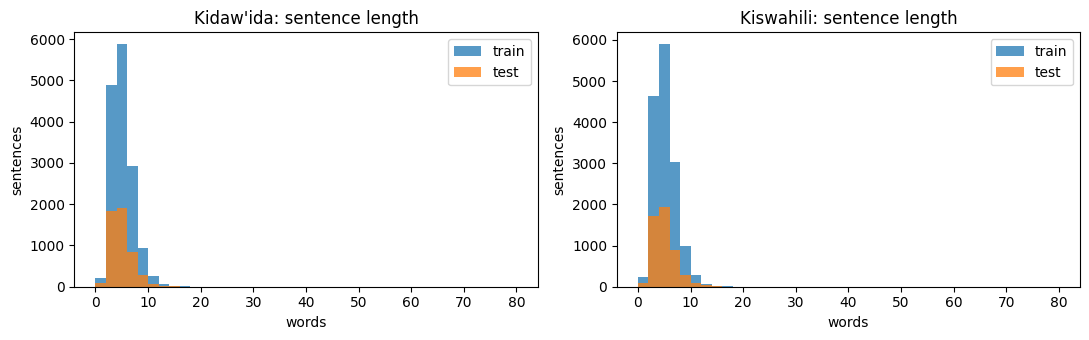

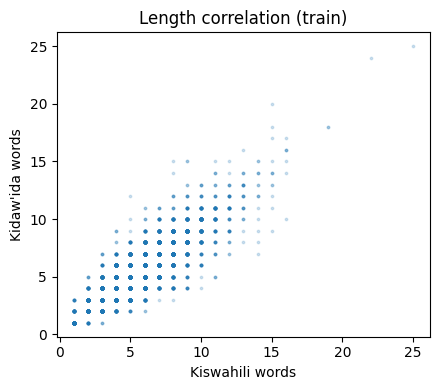

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
bins = range(0, MAX_WORDS + 2, 2)
for ax, lang, title in zip(axes, ['dav', 'swa'], ["Kidaw'ida", 'Kiswahili']):
    ax.hist(train_df[lang].map(n_words), bins=bins, alpha=0.75, label='train')
    ax.hist(test_df[lang].map(n_words),  bins=bins, alpha=0.75, label='test')
    ax.set_title(f'{title}: sentence length'); ax.set_xlabel('words'); ax.set_ylabel('sentences')
    ax.legend()
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/sentence_length_hist.png', dpi=150)
plt.show()

plt.figure(figsize=(4.5, 4))
plt.scatter(train_df.swa.map(n_words), train_df.dav.map(n_words), s=3, alpha=0.2)
plt.xlabel('Kiswahili words'); plt.ylabel("Kidaw'ida words"); plt.title('Length correlation (train)')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/length_scatter.png', dpi=150); plt.show()

## 11. Save cleaned splits, subsets and stats to Drive

In [ ]:
cols = ['id', 'dav', 'swa']
train_df[cols].to_csv(f'{DATA_DIR}/train.csv', index=False)
val_df[cols].to_csv(f'{DATA_DIR}/val.csv', index=False)
test_df[cols].to_csv(f'{DATA_DIR}/test.csv', index=False)
for name, size in subset_sizes.items():
    if name != 'p100':
        train_df[cols].iloc[:size].to_csv(f'{DATA_DIR}/train_{name}.csv', index=False)

summary = {
    'dataset': 'thinkKenya/kenyan-low-resource-language-data (dav_swa)',
    'seed': SEED,
    'filters': {'MAX_WORDS': MAX_WORDS, 'MAX_RATIO': MAX_RATIO, 'MIN_WORDS_FOR_RATIO': MIN_WORDS_FOR_RATIO},
    'raw_report': raw_report,
    'train_filter_log': train_log.to_dict(orient='records'),
    'test_filter_log': test_log.to_dict(orient='records'),
    'leaking_rows_removed_from_train': int(len(leaked)),
    'final_sizes': {'train': len(train_df), 'val': len(val_df), 'test': len(test_df)},
    'subset_sizes': subset_sizes,
    'corpus_stats': stats,
}
with open(f'{RESULTS_DIR}/data_summary.json', 'w') as f:
    json.dump(summary, f, indent=2, default=int)

print(json.dumps(summary['final_sizes'], indent=2))
print('Saved files:', sorted(os.listdir(DATA_DIR)))

{
  "train": 15184,
  "val": 1000,
  "test": 5058
}
Saved files: ['raw', 'test.csv', 'train.csv', 'train_p25.csv', 'train_p50.csv', 'val.csv']


## 12. Sanity check: reload from Drive

In [ ]:
chk = {s: pd.read_csv(f'{DATA_DIR}/{s}.csv', keep_default_na=False) for s in ['train', 'val', 'test']}
for s, d in chk.items():
    assert d.dav.str.len().gt(0).all() and d.swa.str.len().gt(0).all(), f'empty rows in {s}'
assert not set(chk['train'].dav) & set(chk['test'].dav), 'leakage still present!'
assert not set(chk['val'].dav) & set(chk['test'].dav), 'val/test leakage!'
print('All checks passed.')
chk['train'].sample(8, random_state=1)

All checks passed.


,id,dav,swa
9667,912,Mukecha mukevika munighorie niche.,Mukija mukifika muniambie nije.
3856,23115,Kwaw'esekia kii?,Unachekea nini?
4821,23432,Inja maka irikonyi,Ondoa makaa kwenye jiko
3391,21798,Naw'eenda lola mwana shighadinyi.,Ninaenda kumtafuta mtoto nje
14647,6947,Kusekotie kwaki,Usiulize kwanini
13087,16064,Nakulombia charo chipoyie,Nakuombea safari njema
11420,25173,Mwashako wapoisa chia.,Mwashako ametengeneza barabara
4369,3034,Injinia waweagha.,Mhandisi anajengajenga.
